# 2 — Risk differentiation : modélisation (segment SB)

Ce notebook construit le modèle de scoring du segment SB (mono-détenus avec engagement), chapitre 5 du cours. Il part des **37 variables découpées et non redondantes** issues du notebook 1, avec leurs règles de découpage, et des mêmes échantillons d'apprentissage et de test.

**Démarche :**
1. **Modèle concurrent (XGBoost)** : un modèle très flexible, qui donne le niveau de performance maximal atteignable avec ces données. Il sert d'étalon.
2. **Régression logistique** : le modèle retenu pour la grille de score. Les variables sont sélectionnées pas à pas, puis le modèle est contrôlé (significativité, cohérence des coefficients, multicolinéarité) et simplifié.
3. **Comparaison** : la régression logistique est jugée par rapport à XGBoost. Un faible écart de Gini justifie de retenir le modèle interprétable.

**Mesures de performance (5.3).** Toutes les comparaisons reposent sur la capacité du modèle à **classer** les dossiers du plus risqué au moins risqué :
- **AUC** : probabilité qu'un dossier en défaut tiré au hasard ait un score plus risqué qu'un dossier sain tiré au hasard (0,5 = hasard, 1 = classement parfait) ;
- **Gini** = 2 × AUC − 1 (0 = hasard, 1 = parfait) : c'est l'indicateur principal du projet ;
- **KS** : écart maximal entre la répartition des scores des défauts et celle des sains.

## 2.1 Données et échantillons

On charge la base de modélisation exportée par le notebook 1 (variables retenues, valeurs brutes après corrections et feature engineering), les règles de découpage de chaque variable et la synthèse du binning. Les échantillons sont **exactement ceux du notebook 1** : 70 % d'apprentissage et 30 % de test, tirés par client.

In [1]:
# Cellule 1 — paramètres et chargement
from pathlib import Path
import polars as pl
from utils import binning, models
from utils.segmentation import split_train_test

pl.Config.set_tbl_rows(-1); pl.Config.set_tbl_cols(-1); pl.Config.set_tbl_width_chars(200)
pl.Config.set_tbl_hide_column_data_types(True)

ID, TARGET, DATE = "gdt", "ddefaut_ndb", "datdelhis"
CODE = "SB"
base = pl.read_parquet(f"data/processed/base_modele_{CODE}.parquet")
regles = binning.charger_regles(f"outputs/scorecard/regles_{CODE}.json")
selection = pl.read_excel(f"outputs/binning_{CODE}.xlsx", sheet_name=f"{CODE}_Selection")
VARS_MODELE = selection.filter(pl.col("statut") == "retenue")["variable"].to_list()

train, test = base.filter(pl.col("echantillon") == "train"), base.filter(pl.col("echantillon") == "test")
print(len(VARS_MODELE), "variables |", train.height, "lignes train |", test.height, "lignes test")


37 variables | 88629 lignes train | 37996 lignes test


**Échantillon de validation.** Pour choisir certains réglages (le nombre d'arbres de XGBoost, les variables de la régression), il faut mesurer la performance sur des données qui n'ont pas servi à l'estimation. Si on utilisait le test pour ces choix, il ne serait plus un juge neutre et son Gini serait trop optimiste. On met donc de côté **20 % des clients de l'apprentissage** comme échantillon de validation, avec le même tirage par client et la même stratification défaut × mois. Le test reste intouché jusqu'à la mesure finale.

| Échantillon | Rôle |
|---|---|
| estimation (80 % de l'apprentissage) | estimer les modèles |
| validation (20 % de l'apprentissage) | arrêter XGBoost, choisir les variables de la régression |
| test | mesurer la performance finale, une seule fois |

In [2]:
# Cellule 2 — échantillon de validation pour l'arrêt anticipé (20 % des clients du train)
train_v = split_train_test(train.drop("echantillon"), ID, TARGET, [DATE], part_test=0.2, seed=1)
fit = train_v.filter(pl.col("echantillon") == "train")
valid = train_v.filter(pl.col("echantillon") == "test")
print(fit.height, "lignes d'estimation |", valid.height, "lignes de validation")


70909 lignes d'estimation | 17720 lignes de validation


## 2.2 Modèle concurrent : XGBoost

XGBoost assemble des centaines de petits arbres de décision. Il capte sans contrainte les effets non linéaires et les interactions entre variables : son Gini donne donc une idée du **plafond** atteignable avec ces données. Il est estimé deux fois :
- sur les **valeurs brutes** des variables : c'est le plafond de performance ;
- sur la **WOE des classes finales** (chaque valeur remplacée par le poids de sa classe) : XGBoost dispose alors exactement de la même information que la régression logistique, ce qui mesure ce que coûte le découpage lui-même.

Pour limiter le surapprentissage avec environ 1 000 défauts, les arbres sont peu profonds (3 niveaux) et l'ajout d'arbres s'arrête dès que le Gini de validation ne progresse plus (arrêt anticipé). XGBoost reste un modèle de comparaison : il n'est pas retenu comme modèle final, car ses décisions ne se lisent pas sous forme de grille de points (exigence d'interprétabilité du scoring réglementaire).

**Que signifie « XGBoost sur la WOE » ?** Avant d'entraîner cette seconde version, chaque valeur est remplacée par la WOE de **sa classe** (découpage du notebook 1). XGBoost ne voit donc plus les valeurs exactes, seulement la classe dans laquelle tombe chaque client. Exemple avec `horsbilan`, découpée en 3 classes :

| Client | `horsbilan` | Classe | Valeur vue par XGBoost brut | Valeur vue par XGBoost WOE |
|---|---|---|---|---|
| A | 0 | ≤ 0 | 0 | −1,62 |
| B | 150 | 0 à 197,8 | 150 | −0,54 |
| C | 500 | > 197,8 | 500 | +1,32 |
| D | 15 000 | > 197,8 | 15 000 | +1,32 |

XGBoost brut distingue C et D et peut placer ses coupures où il veut ; XGBoost WOE les voit identiques, la variable n'ayant plus que 3 valeurs. Il dispose ainsi **exactement de la même information que la régression logistique**, qui ne connaît elle aussi que la classe de chaque client (à travers ses indicatrices). La WOE plutôt qu'un simple numéro de classe range en outre les classes dans l'ordre du risque, ce qui facilite les coupures des arbres ; l'information est la même.

**Pourquoi deux versions ?** Pour décomposer l'écart de performance entre la régression logistique et le meilleur modèle possible en ses deux causes :

| Comparaison | Ce qui change | Ce que mesure l'écart de Gini |
|---|---|---|
| XGBoost brut → XGBoost WOE | l'information (valeurs exactes → classes), à modèle identique | le coût du **découpage en classes** |
| XGBoost WOE → régression logistique | le modèle (flexible → additif, sans interactions), à information identique | le coût de la **forme de la régression** |

Avec un seul XGBoost, on connaîtrait l'écart total sans savoir s'il faut retravailler le découpage ou s'il s'agit de la limite inhérente à un modèle additif.

In [3]:
# Cellule 3 — XGBoost sur valeurs brutes et sur WOE, mesuré sur le train complet et le test
resultats, modeles = [], {}
for enc in ("brut", "woe"):
    X_fit, X_valid, X_train, X_test = (models.matrice_xgb(d, VARS_MODELE, regles, TARGET, enc, ref=train)
                                        for d in (fit, valid, train, test))
    m = models.entrainer_xgb(X_fit, fit[TARGET], X_valid, valid[TARGET])
    modeles[enc] = (m, X_test)
    resultats += [models.metriques(train[TARGET], m.predict_proba(X_train)[:, 1], f"XGBoost {enc} — train"),
                  models.metriques(test[TARGET], m.predict_proba(X_test)[:, 1], f"XGBoost {enc} — test")]
    print(enc, ": arrêt à", m.best_iteration + 1, "arbres")
print(pl.DataFrame(resultats).select("echantillon", "auc", "gini", "ks"))

brut : arrêt à 328 arbres
woe : arrêt à 198 arbres
shape: (4, 4)
┌──────────────────────┬──────────┬──────────┬──────────┐
│ echantillon          ┆ auc      ┆ gini     ┆ ks       │
╞══════════════════════╪══════════╪══════════╪══════════╡
│ XGBoost brut — train ┆ 0.947692 ┆ 0.895383 ┆ 0.74946  │
│ XGBoost brut — test  ┆ 0.930085 ┆ 0.86017  ┆ 0.722353 │
│ XGBoost woe — train  ┆ 0.9342   ┆ 0.868401 ┆ 0.725455 │
│ XGBoost woe — test   ┆ 0.922619 ┆ 0.845239 ┆ 0.706514 │
└──────────────────────┴──────────┴──────────┴──────────┘


**Résultats.** XGBoost atteint un **Gini test de 0,86** sur les valeurs brutes et de 0,845 sur la WOE des classes finales. L'écart entre apprentissage et test reste limité (3,5 points) : le modèle généralise bien, sans surapprentissage marqué. Le passage des valeurs brutes aux classes ne coûte que 1,5 point de Gini : le découpage du notebook 1 conserve l'essentiel de l'information. La comparaison entre XGBoost WOE et la régression logistique (section 2.4) mesurera ensuite le coût propre à la forme additive de la régression. Ces niveaux servent de référence pour juger la régression logistique.

**Importance des variables (SHAP, 10.1).** L'IV mesure le pouvoir discriminant d'une variable **prise seule**. La valeur SHAP mesure ce que chaque variable apporte réellement aux prédictions de XGBoost **en présence des autres**. Comparer les deux classements est instructif :
- une variable à **forte IV mais faible SHAP** porte une information déjà présente dans d'autres variables : elle est redondante et risque de ne rien apporter à la régression ;
- une variable à **IV modeste mais SHAP élevé** apporte une information complémentaire.

Dans le tableau, `ecart_rang` = rang IV − rang SHAP : négatif, la variable pèse moins que ne le laisse penser son IV ; positif, elle pèse plus.

In [4]:
# Cellule 4 — importance SHAP (XGBoost brut, sur le test) confrontée à l'IV
m, X_test = modeles["brut"]
shap = models.importance_shap(m, X_test, VARS_MODELE)
print(models.confronter_iv_shap(selection, shap)
)

shape: (37, 6)
┌───────────────────────────────┬──────────┬───────────┬─────────┬───────────┬────────────┐
│ variable                      ┆ iv_test  ┆ part_shap ┆ rang_iv ┆ rang_shap ┆ ecart_rang │
╞═══════════════════════════════╪══════════╪═══════════╪═════════╪═══════════╪════════════╡
│ MINSOLDE_PAR                  ┆ 1.495637 ┆ 0.111209  ┆ 5       ┆ 1         ┆ 4          │
│ CRTAE_AG_SLDEPA               ┆ 1.087963 ┆ 0.102273  ┆ 9       ┆ 2         ┆ 7          │
│ TX_UTIL_DAV                   ┆ 1.72771  ┆ 0.08043   ┆ 3       ┆ 3         ┆ 0          │
│ bilan                         ┆ 1.372296 ┆ 0.07665   ┆ 7       ┆ 4         ┆ 3          │
│ solde_crediteur               ┆ 1.73223  ┆ 0.067321  ┆ 2       ┆ 5         ┆ -3         │
│ ARR_GDT                       ┆ 1.689217 ┆ 0.066277  ┆ 4       ┆ 6         ┆ -2         │
│ horsbilan                     ┆ 1.754623 ┆ 0.062767  ┆ 1       ┆ 7         ┆ -6         │
│ anciennete_jour_sain_M0       ┆ 0.61431  ┆ 0.045755  ┆ 17      

**Résultats.** XGBoost repose surtout sur les soldes et encours (`MINSOLDE_PAR`, `CRTAE_AG_SLDEPA`, `TX_UTIL_DAV`, `bilan`, `solde_crediteur`) et sur les arriérés à date (`ARR_GDT`). Plusieurs variables à forte IV pèsent peu une fois les autres présentes : `solde_debiteur` (8e en IV, 33e en SHAP), dont l'information est reprise par le taux d'utilisation du découvert `TX_UTIL_DAV` construit à partir d'elle, `NBJ_ARR_SS` ou `ARR_TENDANCE`, redondantes avec `ARR_GDT`. À l'inverse, `SOLDE_PENTE_4T`, `RATIO_ECR` ou `anciennete_jour_sain_M0` apportent une information complémentaire malgré une IV plus modeste. Ces constats annoncent la sélection de la régression logistique.

**Optimisation des hyperparamètres.** XGBoost sert de plafond de performance : s'il est mal réglé, son Gini est sous-estimé et la comparaison favorise artificiellement la régression logistique. Ses principaux réglages (profondeur des arbres, pas d'apprentissage, taille minimale des feuilles, sous-échantillonnage, régularisation) sont donc choisis par **recherche aléatoire** : 30 combinaisons sont tirées dans une grille, et chacune est évaluée par **validation croisée par client** en 3 plis (un client n'est jamais à la fois en estimation et en validation). La combinaison retenue est celle dont le Gini moyen de validation est le plus élevé. Le test n'intervient pas.


In [5]:
# Cellule 3 bis — optimisation des hyperparamètres de XGBoost (brut), validation croisée par client sur le train
X_train_brut = models.matrice_xgb(train, VARS_MODELE, regles, TARGET, "brut", ref=train)
PARAMS_XGB, essais_xgb = models.optimiser_xgb(X_train_brut, train[TARGET], train[ID], n_essais=30, n_plis=3)
print("meilleure combinaison :", PARAMS_XGB)
print(essais_xgb.head(10))

# Réestimation avec ces réglages (arrêt anticipé sur la validation), mesure sur le test
X_fit, X_valid, X_test_brut = (models.matrice_xgb(d, VARS_MODELE, regles, TARGET, "brut", ref=train) for d in (fit, valid, test))
xgb_opt = models.entrainer_xgb(X_fit, fit[TARGET], X_valid, valid[TARGET], **PARAMS_XGB)
resultats += [models.metriques(train[TARGET], xgb_opt.predict_proba(X_train_brut)[:, 1], "XGBoost optimisé — train"),
              models.metriques(test[TARGET], xgb_opt.predict_proba(X_test_brut)[:, 1], "XGBoost optimisé — test")]
pl.DataFrame(resultats).select("echantillon", "auc", "gini", "ks")


meilleure combinaison : {'max_depth': 6, 'learning_rate': 0.01, 'min_child_weight': 10, 'subsample': 0.6, 'colsample_bytree': 0.7, 'reg_lambda': 10.0, 'gamma': 0.5}
shape: (10, 10)
┌───────────┬───────────────┬──────────────────┬───────────┬──────────────────┬────────────┬───────┬──────────┬────────────────────┬────────────────┐
│ max_depth ┆ learning_rate ┆ min_child_weight ┆ subsample ┆ colsample_bytree ┆ reg_lambda ┆ gamma ┆ gini_cv  ┆ gini_cv_ecart_type ┆ n_arbres_moyen │
╞═══════════╪═══════════════╪══════════════════╪═══════════╪══════════════════╪════════════╪═══════╪══════════╪════════════════════╪════════════════╡
│ 6         ┆ 0.01          ┆ 10               ┆ 0.6       ┆ 0.7              ┆ 10.0       ┆ 0.5   ┆ 0.859129 ┆ 0.00469            ┆ 762.0          │
│ 5         ┆ 0.03          ┆ 10               ┆ 0.8       ┆ 0.9              ┆ 0.1        ┆ 1.0   ┆ 0.858191 ┆ 0.005747           ┆ 140.0          │
│ 6         ┆ 0.01          ┆ 1                ┆ 0.6       ┆ 0.9     

shape: (6, 4)
┌──────────────────────────┬──────────┬──────────┬──────────┐
│ echantillon              ┆ auc      ┆ gini     ┆ ks       │
╞══════════════════════════╪══════════╪══════════╪══════════╡
│ XGBoost brut — train     ┆ 0.947692 ┆ 0.895383 ┆ 0.74946  │
│ XGBoost brut — test      ┆ 0.930085 ┆ 0.86017  ┆ 0.722353 │
│ XGBoost woe — train      ┆ 0.9342   ┆ 0.868401 ┆ 0.725455 │
│ XGBoost woe — test       ┆ 0.922619 ┆ 0.845239 ┆ 0.706514 │
│ XGBoost optimisé — train ┆ 0.95388  ┆ 0.90776  ┆ 0.770269 │
│ XGBoost optimisé — test  ┆ 0.930934 ┆ 0.861868 ┆ 0.729948 │
└──────────────────────────┴──────────┴──────────┴──────────┘

**Résultats.** Les 30 combinaisons essayées donnent des Gini de validation croisée très proches : les dix meilleures se tiennent en 0,3 point (0,856 à 0,859), soit moins que la variabilité entre plis (écart-type d'environ 0,5 point). L'optimum est plat. La meilleure combinaison (arbres de profondeur 6, pas d'apprentissage 0,01, forte régularisation) atteint un Gini test de 0,862, contre 0,860 avec les réglages par défaut : le gain est négligeable, et l'écart apprentissage / test un peu plus élevé (4,6 points contre 3,5). Les réglages par défaut étaient donc déjà proches de l'optimum, et le plafond de performance de ces données est robuste, autour de 0,86.

## 2.3 Régression logistique : sélection des variables 

**Encodage.** Chaque variable entre dans la régression sous forme d'**indicatrices** (une colonne 0/1 par classe). Une classe par variable sert de **référence** et n'a pas d'indicatrice : on prend la **moins risquée**. Le coefficient d'une classe mesure alors le supplément de risque par rapport à cette référence. Conséquence : tous les coefficients doivent être **positifs**, et **croissants** d'une classe à la plus risquée suivante. Un coefficient qui ne respecte pas cet ordre traduit un problème (multicolinéarité, classe instable) et rendrait la grille de score incohérente.

**Sélection pas à pas par ordre de liaison.** Les 37 variables sont essayées une par une, de la plus forte IV à la plus faible. À chaque essai, on ajoute la variable au modèle courant et on ne la **garde que si trois conditions sont réunies** :
1. elle est **significative** : le test du rapport de vraisemblance (modèle avec contre modèle sans la variable) est significatif à 5 % ;
2. elle **améliore le Gini de validation** d'au moins 0,2 point : une variable significative mais qui n'améliore pas le classement n'apporte rien à la grille ;
3. tous les **coefficients du modèle restent cohérents** (positifs et croissants), y compris ceux des variables déjà retenues.

Le modèle est estimé sur l'échantillon d'estimation et le gain de Gini est mesuré sur la validation : le test n'intervient pas. Le journal ci-dessous donne, pour chaque variable, la décision et son motif.

In [6]:
# Cellule 5 — sélection pas à pas par ordre de liaison
ORDRE = selection.filter(pl.col("statut") == "retenue").sort("iv_test", descending=True)["variable"].to_list()
VARS_LOGIT, journal = models.stepwise_liaison(fit, valid, ORDRE, regles, TARGET, alpha=0.05, gain_gini_min=0.002)
print(len(VARS_LOGIT), "variables retenues :", VARS_LOGIT)
print(journal)


10 variables retenues : ['horsbilan', 'solde_crediteur', 'TX_UTIL_DAV', 'ARR_GDT', 'MINSOLDE_PAR', 'CRTAE_AG_SLDEPA', 'ARR_TENDANCE', 'anciennete_jour_sain_M0', 'RATIO_ECR', 'CODITDBDF_PAR']
shape: (37, 7)
┌───────────────────────────────┬───────────┬─────────────┬────────────┬───────────┬──────────┬─────────────────────────────────┐
│ variable                      ┆ n_classes ┆ p_lr        ┆ gini_valid ┆ gain_gini ┆ decision ┆ motif                           │
╞═══════════════════════════════╪═══════════╪═════════════╪════════════╪═══════════╪══════════╪═════════════════════════════════╡
│ horsbilan                     ┆ 3         ┆ 0.0         ┆ 0.622175   ┆ 0.622175  ┆ retenue  ┆                                 │
│ solde_crediteur               ┆ 5         ┆ 1.6366e-131 ┆ 0.765612   ┆ 0.143436  ┆ retenue  ┆                                 │
│ TX_UTIL_DAV                   ┆ 4         ┆ 3.4587e-25  ┆ 0.780573   ┆ 0.014961  ┆ retenue  ┆                                 │
│ ARR_GDT     

**Résultats.** La sélection retient **10 variables sur 37** : `horsbilan`, `solde_crediteur`, `TX_UTIL_DAV`, `ARR_GDT`, `MINSOLDE_PAR`, `CRTAE_AG_SLDEPA`, `ARR_TENDANCE`, `anciennete_jour_sain_M0`, `RATIO_ECR` et `CODITDBDF_PAR`. Les variables écartées le sont :
- pour **gain de Gini insuffisant** : leur information est déjà portée par les variables retenues, comme l'annonçait l'analyse SHAP (`solde_debiteur`, `bilan`, `NBJ_ARR_SS`, `NBJ_ARR_MAX_12M`…) ;
- pour **non-significativité** une fois les autres variables présentes (`ANCIENNETE_modif`, `PART_EPARGNE_DANS_AVOIRS`…) ;
- pour **incohérence des coefficients** (`NBJ_ARR_MAX_13_48M`, `engagement`).

**L'âge** (`AGE_PP_EN_MOIS`) n'est pas significatif (p = 0,68) et n'entre pas dans le modèle : la question de la non-discrimination liée à l'âge ne se pose donc pas pour ce segment.

## 2.4 Modèle final : performance et diagnostics

Une fois les variables choisies, le modèle est **réestimé sur tout l'apprentissage** (estimation + validation), puis mesuré sur le test. Les **erreurs standard sont robustes par client** : environ 2 % des clients sont observés sur plusieurs mois, et leurs lignes ne sont pas indépendantes ; sans cette correction, les tests seraient légèrement trop optimistes.

In [7]:
# Cellule 6 — modèle final réestimé sur tout le train (erreurs standard robustes par client), mesuré sur le test
ORDRES = {v: models.ordre_risque(train, v, regles[v], TARGET) for v in VARS_LOGIT}
X_train_l, NOMS, GROUPES = models.matrice_indicatrices(train, VARS_LOGIT, regles, ORDRES)
X_test_l, _, _ = models.matrice_indicatrices(test, VARS_LOGIT, regles, ORDRES)
logit = models.ajuster_logit(X_train_l, train[TARGET], groupes_clients=train[ID])

perf = pl.DataFrame(resultats + [
    models.metriques(train[TARGET], models.predire(logit, X_train_l), "Régression logistique — train"),
    models.metriques(test[TARGET], models.predire(logit, X_test_l), "Régression logistique — test"),
])
print(perf.select("echantillon", "auc", "gini", "ks"))


shape: (8, 4)
┌───────────────────────────────┬──────────┬──────────┬──────────┐
│ echantillon                   ┆ auc      ┆ gini     ┆ ks       │
╞═══════════════════════════════╪══════════╪══════════╪══════════╡
│ XGBoost brut — train          ┆ 0.947692 ┆ 0.895383 ┆ 0.74946  │
│ XGBoost brut — test           ┆ 0.930085 ┆ 0.86017  ┆ 0.722353 │
│ XGBoost woe — train           ┆ 0.9342   ┆ 0.868401 ┆ 0.725455 │
│ XGBoost woe — test            ┆ 0.922619 ┆ 0.845239 ┆ 0.706514 │
│ XGBoost optimisé — train      ┆ 0.95388  ┆ 0.90776  ┆ 0.770269 │
│ XGBoost optimisé — test       ┆ 0.930934 ┆ 0.861868 ┆ 0.729948 │
│ Régression logistique — train ┆ 0.918053 ┆ 0.836106 ┆ 0.700891 │
│ Régression logistique — test  ┆ 0.907519 ┆ 0.815038 ┆ 0.689598 │
└───────────────────────────────┴──────────┴──────────┴──────────┘


**Résultats.** La régression logistique atteint un **Gini test de 0,815**, contre 0,845 pour XGBoost sur la même information et 0,86 sur les valeurs brutes. L'écart total de 4,5 points avec le plafond se décompose en 1,5 point dû au découpage en classes (XGBoost brut → XGBoost WOE) et 3 points dû à la forme additive de la régression (XGBoost WOE → régression). Un modèle interprétable, présentable sous forme de grille de points, au prix de 3 points de Gini : c'est ce qui justifie de le retenir. L'écart entre apprentissage et test (2 points) confirme l'absence de surapprentissage.

**Diagnostics (5.1, 5.4).** Trois contrôles sur le modèle retenu :
- **tests par variable** : rapport de vraisemblance (retrait de toutes les indicatrices de la variable) et test de Wald conjoint, calculé avec les erreurs standard robustes par client. Une variable non significative n'a pas sa place dans le modèle ;
- **odds ratios** : l'exponentielle du coefficient d'une classe. Un odds ratio de 2 signifie que la cote de défaut (probabilité de défaut / probabilité de non-défaut) est deux fois plus élevée que dans la classe de référence, toutes choses égales par ailleurs. L'intervalle de confiance à 95 % montre la précision de l'estimation ; s'il contient 1, la classe ne se distingue pas significativement de la référence ;
- **VIF** (facteur d'inflation de la variance) : mesure à quel point une indicatrice est expliquée par les autres. Au-delà de 5, la multicolinéarité rend les coefficients instables ; au-delà de 10, elle est sévère.

In [8]:
# Cellule 7 — diagnostics : tests par variable, odds ratios, VIF, cohérence des coefficients
print(models.tests_par_variable(logit, X_train_l, train[TARGET], GROUPES))
print(models.odds_ratios(logit, NOMS))
print(models.vif_indicatrices(X_train_l, NOMS))
print("coefficients cohérents :", models.coefficients_coherents(logit, GROUPES))


shape: (10, 6)
┌─────────────────────────┬─────┬────────────┬────────────┬────────────┬────────────┐
│ variable                ┆ ddl ┆ lr         ┆ p_lr       ┆ wald       ┆ p_wald     │
╞═════════════════════════╪═════╪════════════╪════════════╪════════════╪════════════╡
│ ARR_TENDANCE            ┆ 2   ┆ 264.191038 ┆ 4.2820e-58 ┆ 227.537679 ┆ 3.8978e-50 │
│ CODITDBDF_PAR           ┆ 1   ┆ 69.451381  ┆ 7.8322e-17 ┆ 72.548288  ┆ 1.6299e-17 │
│ solde_crediteur         ┆ 4   ┆ 68.630117  ┆ 4.4169e-14 ┆ 60.058075  ┆ 2.8205e-12 │
│ TX_UTIL_DAV             ┆ 3   ┆ 51.546144  ┆ 3.7422e-11 ┆ 47.06123   ┆ 3.3729e-10 │
│ anciennete_jour_sain_M0 ┆ 3   ┆ 48.010309  ┆ 2.1188e-10 ┆ 43.805107  ┆ 1.6601e-9  │
│ CRTAE_AG_SLDEPA         ┆ 3   ┆ 46.20797   ┆ 5.1224e-10 ┆ 39.511064  ┆ 1.3526e-8  │
│ RATIO_ECR               ┆ 2   ┆ 43.380976  ┆ 3.8014e-10 ┆ 42.444777  ┆ 6.0706e-10 │
│ ARR_GDT                 ┆ 1   ┆ 33.578257  ┆ 6.8454e-9  ┆ 29.065391  ┆ 6.9976e-8  │
│ MINSOLDE_PAR            ┆ 2   ┆ 23.70

**Résultats.** Les 10 variables sont toutes très significatives, en rapport de vraisemblance comme en Wald robuste (p < 0,002). Les VIF restent tous inférieurs à 2,6 : aucune multicolinéarité. En revanche, l'examen des odds ratios **classe par classe** montre que quatre modalités, toutes voisines de la classe de référence, ne s'en distinguent pas significativement (p > 0,2, intervalle de confiance contenant largement 1) ; une cinquième, `solde_crediteur` ]1 600 ; 5 500], est à la limite (p = 0,05). L'une d'elles, `RATIO_ECR` ]0,5 ; 0,99], a même un coefficient légèrement négatif, donc incohérent.

## 2.5 Test par modalité et regroupement 

Une modalité qui ne se distingue pas de la classe de référence n'apporte rien au modèle et complique la grille de score. Le traitement prévu par le cours est de la **fusionner avec la classe de référence**, puis de réestimer le modèle et de vérifier que la performance ne baisse pas. Les quatre modalités concernées sont :

| Variable | Modalité fusionnée avec la référence | Coefficient avant | p |
|---|---|---|---|
| `RATIO_ECR` | ]0,5 ; 0,99] | −0,02 (incohérent) | 0,88 |
| `TX_UTIL_DAV` | ]1 ; 3,7] | 0,20 | 0,32 |
| `horsbilan` | ]0 ; 197,8] | 0,18 | 0,20 |
| `solde_crediteur` | ]5 500 ; 30 000] | 0,26 | 0,20 |

Techniquement, fusionner deux classes voisines revient à retirer la borne qui les sépare. Les règles de découpage du modèle final sont sauvegardées à part (`regles_modele_SB.json`), sans modifier celles du notebook 1.

In [9]:
# Cellule 8 — regroupement des modalités non significatives avec la classe de référence (test par modalité, 5.1)
BORNES_A_RETIRER = {
    "RATIO_ECR": [0.5],            # ]-inf ; 0,5] + ]0,5 ; 0,99] : coefficient nul et de signe incohérent
    "TX_UTIL_DAV": [1.0],          # ]-inf ; 1] + ]1 ; 3,7]
    "horsbilan": [197.75],         # ]0 ; 197,8] + ]197,8 ; +inf]
    "solde_crediteur": [30000.0],  # ]5 500 ; 30 000] + ]30 000 ; +inf]
}
regles_modele = regles | {v: models.retirer_bornes(regles[v], b) for v, b in BORNES_A_RETIRER.items()}

ORDRES = {v: models.ordre_risque(train, v, regles_modele[v], TARGET) for v in VARS_LOGIT}
X_train_l, NOMS, GROUPES = models.matrice_indicatrices(train, VARS_LOGIT, regles_modele, ORDRES)
X_test_l, _, _ = models.matrice_indicatrices(test, VARS_LOGIT, regles_modele, ORDRES)
logit = models.ajuster_logit(X_train_l, train[TARGET], groupes_clients=train[ID])

print(pl.DataFrame([
    models.metriques(train[TARGET], models.predire(logit, X_train_l), "Logistique regroupée — train"),
    models.metriques(test[TARGET], models.predire(logit, X_test_l), "Logistique regroupée — test"),
]).select("echantillon", "auc", "gini", "ks"))
print(models.odds_ratios(logit, NOMS))
print("coefficients cohérents :", models.coefficients_coherents(logit, GROUPES))
binning.sauver_regles(regles_modele, f"outputs/scorecard/regles_modele_{CODE}.json")


shape: (2, 4)
┌──────────────────────────────┬──────────┬──────────┬──────────┐
│ echantillon                  ┆ auc      ┆ gini     ┆ ks       │
╞══════════════════════════════╪══════════╪══════════╪══════════╡
│ Logistique regroupée — train ┆ 0.917601 ┆ 0.835202 ┆ 0.699471 │
│ Logistique regroupée — test  ┆ 0.90757  ┆ 0.815141 ┆ 0.691356 │
└──────────────────────────────┴──────────┴──────────┴──────────┘
shape: (20, 6)
┌─────────────────────────────────┬─────────────┬────────────┬────────────┬─────────────┬──────────────┐
│ terme                           ┆ coefficient ┆ p_value    ┆ odds_ratio ┆ or_ic95_bas ┆ or_ic95_haut │
╞═════════════════════════════════╪═════════════╪════════════╪════════════╪═════════════╪══════════════╡
│ constante                       ┆ -7.822091   ┆ 0.0        ┆ 0.000401   ┆ 0.00028     ┆ 0.000573     │
│ horsbilan = ]-inf ; 0]          ┆ 0.416655    ┆ 0.000686   ┆ 1.516879   ┆ 1.192573    ┆ 1.929375     │
│ solde_crediteur = ]1600 ; 5500… ┆ 0.22988     ┆ 

**Résultats.** Après regroupement, le modèle compte **19 indicatrices au lieu de 23**, **tous les coefficients sont positifs et croissants** avec le risque, et le **Gini test est inchangé (0,815)**. La grille de score sera donc plus simple, sans perte de performance. Une modalité reste à la limite de la significativité (`solde_crediteur` ]1 600 ; 5 500], p = 0,07) ; elle est conservée, car son coefficient est cohérent (compris entre ceux de ses voisines) et la variable est globalement très significative.

## 2.6 Comparaison des modèles

Les Gini sont mesurés sur un échantillon de test de taille finie (470 défauts) : chacun comporte une part d'incertitude. Pour juger si les écarts entre modèles sont réels, on calcule des **intervalles de confiance par bootstrap** : on retire 1 000 fois les clients du test au hasard, avec remise (toutes les lignes d'un client tiré sont reprises, ce qui respecte la dépendance entre ses mois d'observation), et on recalcule à chaque fois le Gini de chaque modèle. L'intervalle porte aussi sur l'**écart** entre chaque modèle et la régression logistique, calculé sur les mêmes tirages : si cet intervalle ne contient pas 0, la différence est statistiquement significative. Les courbes ROC complètent la comparaison visuellement.


shape: (4, 4)
┌───────────────────────┬──────────┬──────────┬──────────┐
│ modele                ┆ gini     ┆ ic_bas   ┆ ic_haut  │
╞═══════════════════════╪══════════╪══════════╪══════════╡
│ XGBoost brut optimisé ┆ 0.861868 ┆ 0.839323 ┆ 0.881624 │
│ XGBoost brut          ┆ 0.86017  ┆ 0.8379   ┆ 0.881287 │
│ XGBoost WOE           ┆ 0.845239 ┆ 0.822218 ┆ 0.868187 │
│ Régression logistique ┆ 0.815141 ┆ 0.789946 ┆ 0.838507 │
└───────────────────────┴──────────┴──────────┴──────────┘
shape: (3, 6)
┌───────────────────────┬───────────────────────┬────────────┬──────────┬──────────┬──────────────┐
│ modele                ┆ reference             ┆ ecart_gini ┆ ic_bas   ┆ ic_haut  ┆ significatif │
╞═══════════════════════╪═══════════════════════╪════════════╪══════════╪══════════╪══════════════╡
│ XGBoost brut optimisé ┆ Régression logistique ┆ 0.046727   ┆ 0.037471 ┆ 0.056558 ┆ true         │
│ XGBoost brut          ┆ Régression logistique ┆ 0.045029   ┆ 0.035797 ┆ 0.054936 ┆ true         │


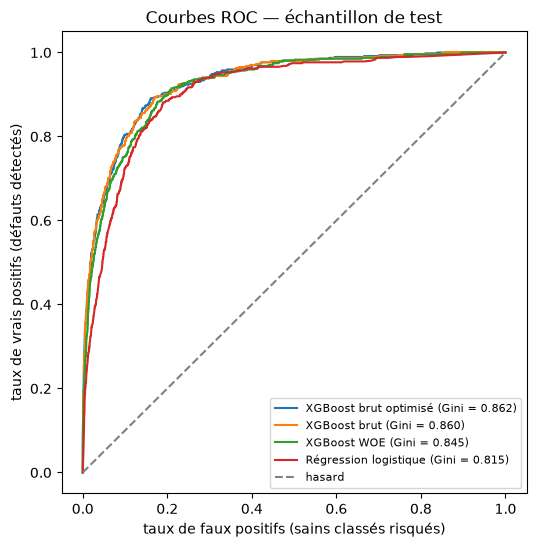

In [10]:
# Cellule 9 — comparaison des modèles sur le test : intervalles de confiance par bootstrap (par client) et courbes ROC
import matplotlib.pyplot as plt

X_test_woe = models.matrice_xgb(test, VARS_MODELE, regles, TARGET, "woe", ref=train)
SCORES = {
    "XGBoost brut optimisé": xgb_opt.predict_proba(X_test_brut)[:, 1],
    "XGBoost brut": modeles["brut"][0].predict_proba(X_test_brut)[:, 1],
    "XGBoost WOE": modeles["woe"][0].predict_proba(X_test_woe)[:, 1],
    "Régression logistique": models.predire(logit, X_test_l),
}
gini_ic, ecarts_ic = models.gini_bootstrap(test[TARGET], SCORES, test[ID], reference="Régression logistique", n_tirages=1000)
print(gini_ic); print(ecarts_ic)
models.courbes_roc(test[TARGET], SCORES); plt.show()


**Résultats.** Tous les modèles XGBoost font significativement mieux que la régression logistique : l'intervalle de confiance de l'écart ne contient jamais 0. L'écart est de 4,5 à 4,7 points de Gini face aux versions sur valeurs brutes (IC à 95 % : environ [3,6 ; 5,7]) et de 3,0 points face à XGBoost sur la WOE ([2,3 ; 3,9]), qui dispose de la même information que la régression. Les intervalles individuels se chevauchent, mais la comparaison pertinente est celle de l'écart, calculé sur les mêmes tirages de clients.

Cet écart, réel mais modéré, est le prix de l'interprétabilité : la régression logistique se traduit en une grille de points lisible, dont chaque coefficient est justifiable, ce qui est exigé en scoring réglementaire. Avec 470 défauts dans le test, le Gini de chaque modèle est connu à environ ± 2,5 points près ; des écarts inférieurs au point entre variantes d'un même modèle ne sont donc pas interprétables.

## Bilan du chapitre 5 pour le segment SB

| Modèle | Variables | Gini train | Gini test | IC à 95 % (test) |
|---|---|---|---|---|
| XGBoost, valeurs brutes, optimisé | 37 | 0,908 | 0,862 | [0,839 ; 0,882] |
| XGBoost, valeurs brutes | 37 | 0,895 | 0,860 | [0,838 ; 0,881] |
| XGBoost, WOE des classes | 37 | 0,868 | 0,845 | [0,822 ; 0,868] |
| **Régression logistique retenue** | **10 (19 indicatrices)** | **0,835** | **0,815** | **[0,790 ; 0,839]** |

La régression logistique retenue est **parcimonieuse** (10 variables), **cohérente** (tous les coefficients ordonnés selon le risque), **stable** (2 points d'écart entre apprentissage et test) et **proche du plafond de performance** (3 à 4,7 points de Gini de moins que XGBoost, écart significatif mais modéré). Elle repose sur quatre familles de risk drivers : les soldes et encours du compte, l'utilisation du découvert, les arriérés et l'historique de défaut, et l'activité du compte.

**Étape suivante** : traduction des coefficients en grille de points (chapitre 6, méthode PDO).